Helpers agree with StatevectorEstimator. Max difference: 4.718447854656915e-16
Max |C_trotter - C_exact| over all pairs and times: 0.0203


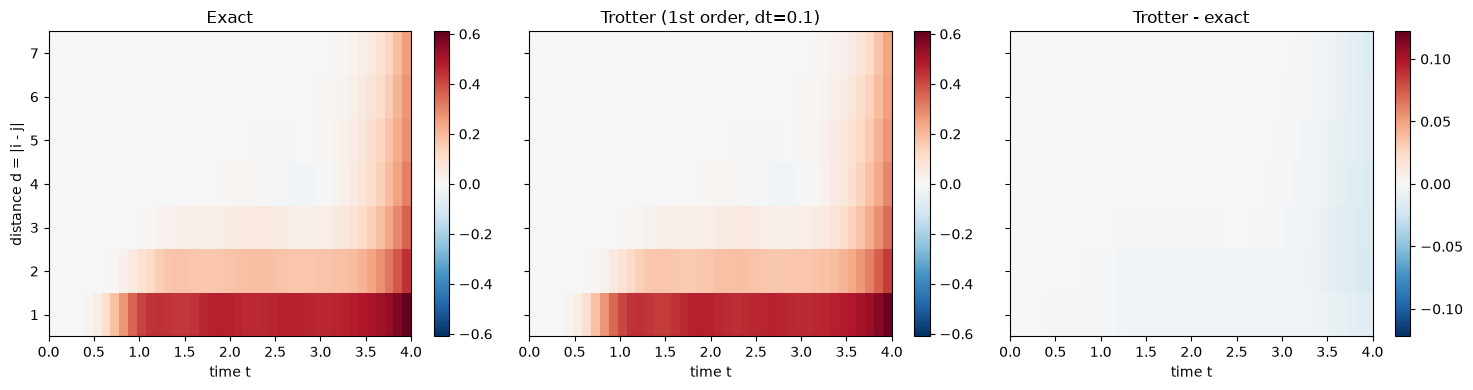

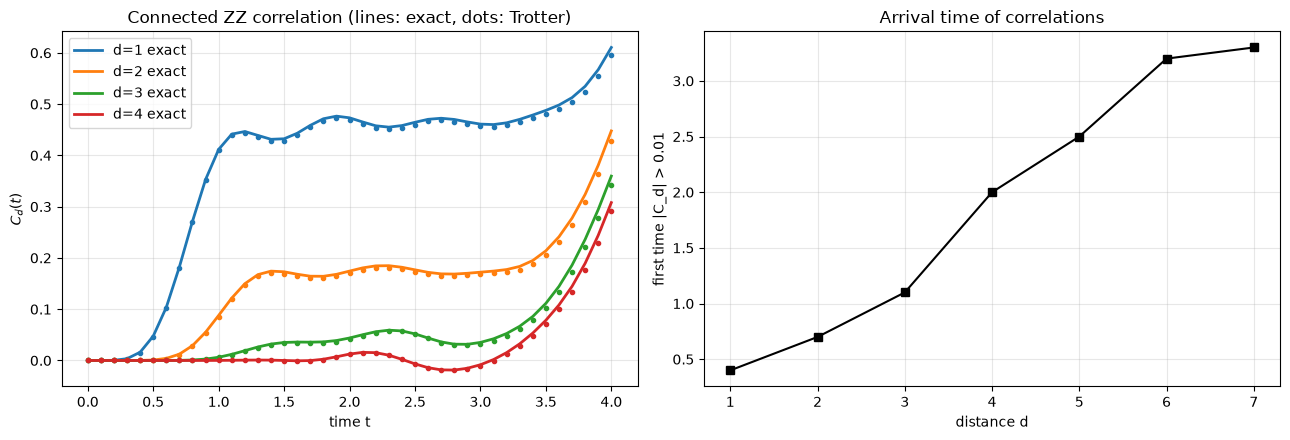

d=1: correlation first exceeds 0.01 at t = 0.40
d=2: correlation first exceeds 0.01 at t = 0.70
d=3: correlation first exceeds 0.01 at t = 1.10
d=4: correlation first exceeds 0.01 at t = 2.00
d=5: correlation first exceeds 0.01 at t = 2.50
d=6: correlation first exceeds 0.01 at t = 3.20
d=7: correlation first exceeds 0.01 at t = 3.30
   n      dt  err_state     err_Mz     err_Mx
   2  1.5000   1.04e+00   1.02e+00   4.47e-01
   3  1.0000   1.27e+00   5.51e-01   5.32e-01
   4  0.7500   8.55e-01   2.72e-01   4.83e-01
   5  0.6000   8.42e-01   1.40e-01   6.83e-01
   6  0.5000   6.97e-01   7.65e-02   6.24e-01
   8  0.3750   4.79e-01   4.40e-02   4.23e-01
  10  0.3000   3.57e-01   2.63e-02   3.01e-01
  12  0.2500   2.83e-01   1.82e-02   2.28e-01
  15  0.2000   2.14e-01   1.12e-02   1.64e-01
  20  0.1500   1.52e-01   6.34e-03   1.11e-01
  24  0.1250   1.24e-01   4.38e-03   9.17e-02
  30  0.1000   9.62e-02   2.82e-03   7.11e-02
  40  0.0750   7.03e-02   1.57e-03   5.06e-02
  60  0.0500   4.56e

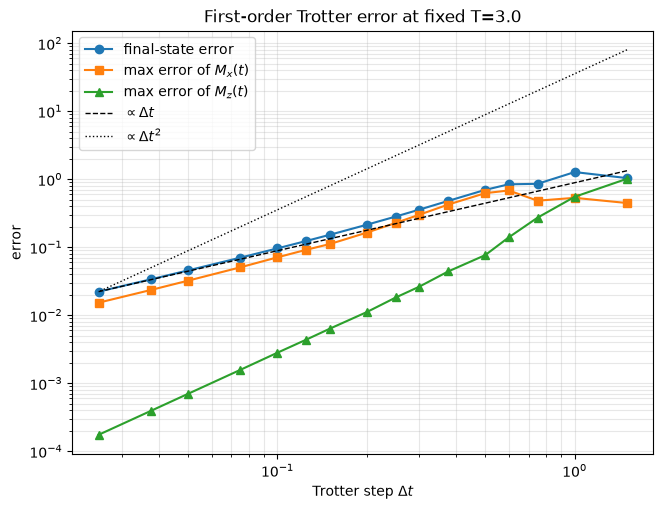

fitted slope of err_state vs dt (dt <= 0.2): 1.09
fitted slope of err_mx vs dt (dt <= 0.2): 1.13
fitted slope of err_mz vs dt (dt <= 0.2): 2.00
Fixed final time T = 3.0. Largest dt that stays within tolerance (all smaller dt also pass):

err_state <= 0.1  : dt = 0.100  (n = 30 steps)
err_state <= 0.05 : dt = 0.050  (n = 60 steps)
   err_mx <= 0.02 : dt = 0.025  (n = 120 steps)
   err_mz <= 0.01 : dt = 0.150  (n = 20 steps)
First order: 6.0 CNOTs per Trotter step (= 2 per ZZ term x 3 ZZ terms).


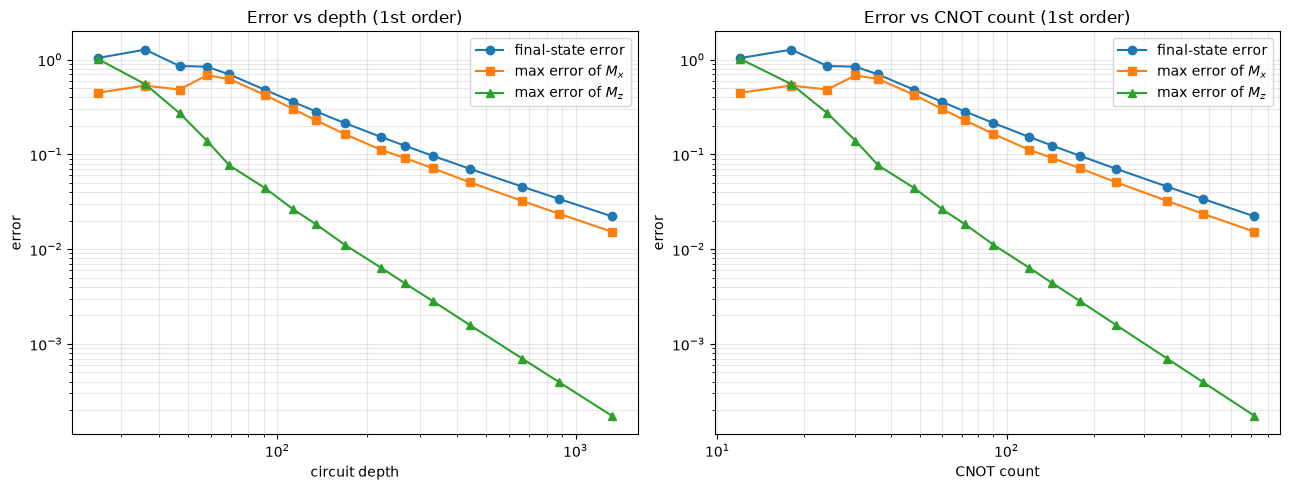


Cheapest first-order circuit reaching a state-error target:
  err_state <= 0.2  : n= 20 steps, depth= 223, CNOTs= 120
  err_state <= 0.1  : n= 30 steps, depth= 333, CNOTs= 180
  err_state <= 0.05 : n= 60 steps, depth= 663, CNOTs= 360
  err_state <= 0.02 : not reached
order 1: CNOTs per step ~ 6.0, fitted state-error slope = 1.15, M_x slope = 1.24
order 2: CNOTs per step ~ 10.0, fitted state-error slope = 2.02, M_x slope = 2.03
order 4: CNOTs per step ~ 50.1, fitted state-error slope = 3.96, M_x slope = 3.71

M_z error identical for order 1 and order 2 at every n: True


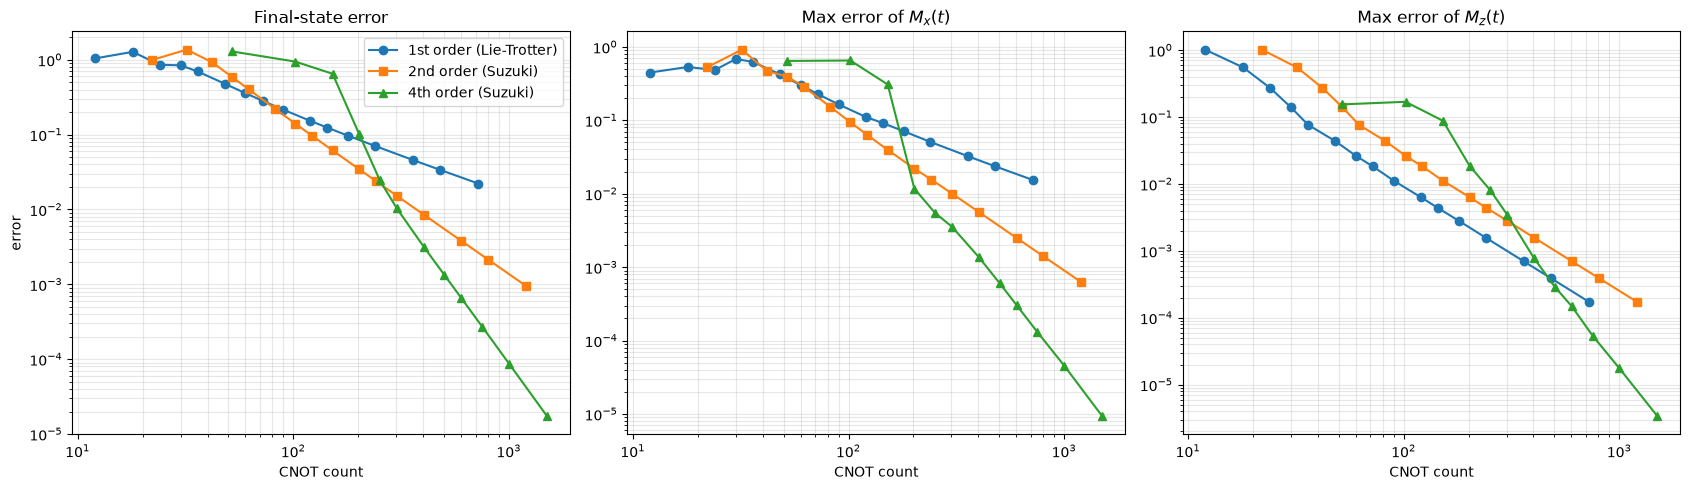

Cheapest circuit (fewest CNOTs) reaching each final-state error target:

  target |        order 1         |        order 2         |        order 4        
-----------------------------------------------------------------------------------
   1e-01 |   n= 30,   180 CNOTs   |   n= 12,   122 CNOTs   |   n=  5,   252 CNOTs  
   3e-02 |   n=120,   720 CNOTs   |   n= 24,   242 CNOTs   |   n=  5,   252 CNOTs  
   1e-02 |      not reached       |   n= 40,   402 CNOTs   |   n=  8,   402 CNOTs  
   1e-03 |      not reached       |   n=120,  1202 CNOTs   |   n= 12,   602 CNOTs  
   1e-04 |      not reached       |      not reached       |   n= 20,  1002 CNOTs  


In [ ]:
# Beginner Challenge - Understanding Our TFIM Simulation
# Continues: Simulating Quantum Dynamics: The Transverse-Field Ising Model (B. Tirado, BasQ Qiskit Fall Fest 2026)
# Builds on that notebook (text CC BY 4.0, code Apache-2.0). tfim_hamiltonian and
# trotter_evolution_circuit are copied from it; everything else was added for the Beginner challenge.
#
# Sections: 1 Correlations | 2 Trotter step size | 3 Accuracy vs depth | 4 Higher-order Trotter

# =====================================================================
# Setup and helpers
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter, SuzukiTrotter
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.primitives import StatevectorEstimator
from qiskit_ibm_runtime import QiskitRuntimeService

# ---- copied unchanged from the tutorial ----
service = QiskitRuntimeService()

backend = service.least_busy(simulator=False, operational=True)

# Convert to an ISA circuit and layout-mapped observables.
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc)

isa_circuit.draw("mpl", idle_wires=False)
def tfim_hamiltonian(num_qubits, J=1.0, h=1.0):
    """Transverse-field Ising Hamiltonian on an open chain as a SparsePauliOp."""
    terms = []
    for i in range(num_qubits - 1):
        pauli = ["I"] * num_qubits
        pauli[i] = "Z"
        pauli[i + 1] = "Z"
        terms.append(("".join(reversed(pauli)), -J))
    for i in range(num_qubits):
        pauli = ["I"] * num_qubits
        pauli[i] = "X"
        terms.append(("".join(reversed(pauli)), -h))
    return SparsePauliOp.from_list(terms)


def trotter_evolution_circuit(H, num_qubits, dt, n_steps, order=1):
    """Prepare |00..0> and apply n_steps Trotter steps of size dt."""
    if order == 1:
        synth = LieTrotter(reps=1)
    else:
        synth = SuzukiTrotter(order=order, reps=1)
    qc = QuantumCircuit(num_qubits)
    qc.barrier()
    step = PauliEvolutionGate(H, time=dt, synthesis=synth)
    for _ in range(n_steps):
        qc.append(step, range(num_qubits))
    return qc.decompose(reps=2)
# ---- new helpers ----
def site_op(num_qubits, paulis, coeff=1.0):
    """Pauli string from {site: 'Z'/'X'/...}; e.g. {1: 'Z', 3: 'Z'} -> Z_1 Z_3."""
    label = "".join(paulis.get(i, "I") for i in reversed(range(num_qubits)))
    return SparsePauliOp.from_list([(label, coeff)])


def avg_op(num_qubits, p):
    """(1/N) * sum_i P_i for a single-site Pauli letter p."""
    terms = [("".join(p if k == i else "I" for k in reversed(range(num_qubits))), 1.0 / num_qubits)
             for i in range(num_qubits)]
    return SparsePauliOp.from_list(terms)


def trotter_states(H, num_qubits, dt, n_steps, order=1):
    """States after 0, 1, ..., n_steps Trotter steps (time t_n = n*dt)."""
    one_step = trotter_evolution_circuit(H, num_qubits, dt, 1, order)
    sv = Statevector.from_label("0" * num_qubits)
    states = [sv]
    for _ in range(n_steps):
        sv = sv.evolve(one_step)
        states.append(sv)
    return states


def exact_states(H, times):
    """Exact exp(-iHt)|0..0> for each t in times (classical, small N only)."""
    N = H.num_qubits
    w, V = np.linalg.eigh(H.to_matrix())
    c = V.conj().T @ Statevector.from_label("0" * N).data
    return [Statevector(V @ (np.exp(-1j * w * t) * c)) for t in times]


def state_error(exact, approx):
    """2-norm distance between two states after removing the global phase."""
    o = np.vdot(exact.data, approx.data)
    phase = o / abs(o)
    return float(np.linalg.norm(approx.data * np.conj(phase) - exact.data))


def circuit_cost(H, num_qubits, dt, n_steps, order=1):
    """(depth, #CNOT) of the n_steps circuit after transpiling to rz/sx/x/cx."""
    qc = trotter_evolution_circuit(H, num_qubits, dt, n_steps, order)
    tqc = transpile(qc, basis_gates=["rz", "sx", "x", "cx"], optimization_level=1)
    return tqc.depth(), tqc.count_ops().get("cx", 0)


# ---- Sanity check: helpers must reproduce the tutorial's StatevectorEstimator result ----
N0, dt0, n0 = 4, 0.2, 10
H0 = tfim_hamiltonian(N0, 1.0, 1.0)
Mz0 = avg_op(N0, "Z")

est = StatevectorEstimator()
mz_est = [float(est.run([(trotter_evolution_circuit(H0, N0, dt0, n, order=1), Mz0)]).result()[0].data.evs)
          for n in range(n0 + 1)]
mz_help = [s.expectation_value(Mz0).real for s in trotter_states(H0, N0, dt0, n0, order=1)]

assert np.allclose(mz_est, mz_help, atol=1e-8), "helpers disagree with the Estimator!"
print("Helpers agree with StatevectorEstimator. Max difference:", np.max(np.abs(np.array(mz_est) - mz_help)))

# =====================================================================
# 1. Correlations: how does information spread?
# =====================================================================
# Connected correlator C_ij(t) = <Z_i Z_j> - <Z_i><Z_j>. At t=0 the state is a product state,
# so C_ij(0) = 0: any correlation seen later is created by the dynamics.
# N=8 chain; pairs at the same distance d=|i-j| are averaged (open-chain boundary effects):
# C_d(t) = 1/(N-d) * sum_i C_{i,i+d}(t). First-order Trotter (dt=0.1) vs exact.
Nc, Jc, hc = 8, 1.0, 1.0
dtc, nsteps_c = 0.1, 40                     # final time T = 4
Hc = tfim_hamiltonian(Nc, Jc, hc)
times_c = dtc * np.arange(nsteps_c + 1)

single_ops = [site_op(Nc, {i: "Z"}) for i in range(Nc)]
pair_ops = {(i, j): site_op(Nc, {i: "Z", j: "Z"}) for i in range(Nc) for j in range(i + 1, Nc)}

def connected_correlations(states):
    """C[t, i, j] = <Z_i Z_j> - <Z_i><Z_j> (zero on the diagonal block we never use)."""
    C = np.zeros((len(states), Nc, Nc))
    for t, sv in enumerate(states):
        z = [sv.expectation_value(op).real for op in single_ops]
        for (i, j), op in pair_ops.items():
            C[t, i, j] = C[t, j, i] = sv.expectation_value(op).real - z[i] * z[j]
    return C

def distance_average(C):
    return np.array([[np.mean([C[t, i, i + d] for i in range(Nc - d)]) for t in range(C.shape[0])]
                     for d in range(1, Nc)])          # shape (Nc-1, T): row d-1 is distance d

C_trot = connected_correlations(trotter_states(Hc, Nc, dtc, nsteps_c, order=1))
C_exact = connected_correlations(exact_states(Hc, times_c))
Cd_trot, Cd_exact = distance_average(C_trot), distance_average(C_exact)

print("Max |C_trotter - C_exact| over all pairs and times:", np.max(np.abs(C_trot - C_exact)).round(4))
vmax = np.max(np.abs(Cd_exact))
ext = [0, times_c[-1], 0.5, Nc - 0.5]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, data, title, vm in [(axes[0], Cd_exact, "Exact", vmax),
                            (axes[1], Cd_trot, f"Trotter (1st order, dt={dtc})", vmax),
                            (axes[2], Cd_trot - Cd_exact, "Trotter - exact", vmax / 5)]:
    im = ax.imshow(data, origin="lower", aspect="auto", extent=ext, cmap="RdBu_r", vmin=-vm, vmax=vm)
    ax.set_title(title); ax.set_xlabel("time t")
    fig.colorbar(im, ax=ax)
axes[0].set_ylabel("distance d = |i - j|")
plt.tight_layout(); plt.show()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for d in range(1, 5):
    line, = ax1.plot(times_c, Cd_exact[d - 1], lw=2, label=f"d={d} exact")
    ax1.plot(times_c, Cd_trot[d - 1], "o", ms=3, color=line.get_color())
ax1.set_xlabel("time t"); ax1.set_ylabel(r"$C_d(t)$"); ax1.grid(alpha=0.3)
ax1.set_title("Connected ZZ correlation (lines: exact, dots: Trotter)"); ax1.legend()

# Onset time: first time |C_d| exceeds a small threshold
thr = 0.01
dists, onsets = [], []
for d in range(1, Nc):
    hit = np.abs(Cd_exact[d - 1]) > thr
    if hit.any():
        dists.append(d); onsets.append(times_c[np.argmax(hit)])
ax2.plot(dists, onsets, "ks-")
ax2.set_xlabel("distance d"); ax2.set_ylabel(f"first time |C_d| > {thr}")
ax2.set_title("Arrival time of correlations"); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

for d, t0 in zip(dists, onsets):
    print(f"d={d}: correlation first exceeds {thr} at t = {t0:.2f}")

# What to read from these plots:
# - Correlations start at zero; nearest-neighbour ones appear first, larger distances switch on later
#   (a light-cone delay).
# - The heatmap shows a front moving outward; at late times it reflects off the open boundaries
#   (finite-size effect, not Trotter error).
# - The difference panel (5x tighter colour scale) shows error is small early and grows with t.

# =====================================================================
# 2. Trotter step size: how small is small enough?
# =====================================================================
# 4-spin chain, fixed final time T=3 reached with n steps of size dt=T/n. Errors vs exact:
#   err_state: distance between final states, err_Mz / err_Mx: worst-case magnetization errors.
# M_z alone hides the O(dt) scaling (explained after the plot).
N4, J4, h4, T = 4, 1.0, 1.0, 3.0
H4 = tfim_hamiltonian(N4, J4, h4)
Mz4, Mx4 = avg_op(N4, "Z"), avg_op(N4, "X")

def sweep(order, n_list):
    """Errors and circuit cost for reaching time T in n steps, for each n in n_list."""
    rows = []
    for n in n_list:
        dt = T / n
        t = dt * np.arange(n + 1)
        tr, ex = trotter_states(H4, N4, dt, n, order), exact_states(H4, t)
        err_mz = max(abs(a.expectation_value(Mz4).real - b.expectation_value(Mz4).real) for a, b in zip(tr, ex))
        err_mx = max(abs(a.expectation_value(Mx4).real - b.expectation_value(Mx4).real) for a, b in zip(tr, ex))
        depth, cx = circuit_cost(H4, N4, dt, n, order)
        rows.append(dict(n=n, dt=dt, err_state=state_error(ex[-1], tr[-1]),
                         err_mz=err_mz, err_mx=err_mx, depth=depth, cx=cx))
    return rows

col = lambda rows, k: np.array([r[k] for r in rows])

results = {}
n_list = [2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 24, 30, 40, 60, 80, 120]
results[1] = sweep(1, n_list)

print(f"{'n':>4} {'dt':>7} {'err_state':>10} {'err_Mz':>10} {'err_Mx':>10}")
for r in results[1]:
    print(f"{r['n']:>4} {r['dt']:>7.4f} {r['err_state']:>10.2e} {r['err_mz']:>10.2e} {r['err_mx']:>10.2e}")
def fit_slope(rows, key, dt_max=0.2):
    dt, err = col(rows, "dt"), col(rows, key)
    m = (dt <= dt_max) & (err > 1e-12)
    return np.polyfit(np.log(dt[m]), np.log(err[m]), 1)[0]

rows = results[1]
dt_arr = col(rows, "dt")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.loglog(dt_arr, col(rows, "err_state"), "o-", label="final-state error")
ax.loglog(dt_arr, col(rows, "err_mx"), "s-", label=r"max error of $M_x(t)$")
ax.loglog(dt_arr, col(rows, "err_mz"), "^-", label=r"max error of $M_z(t)$")
ref = col(rows, "err_state")[-1] / dt_arr[-1]
ax.loglog(dt_arr, ref * dt_arr, "k--", lw=1, label=r"$\propto \Delta t$")
ax.loglog(dt_arr, ref * dt_arr[-1] * (dt_arr / dt_arr[-1]) ** 2, "k:", lw=1, label=r"$\propto \Delta t^2$")
ax.set_xlabel(r"Trotter step $\Delta t$"); ax.set_ylabel("error"); ax.grid(alpha=0.3, which="both")
ax.set_title(f"First-order Trotter error at fixed T={T}"); ax.legend()
plt.show()

for key in ("err_state", "err_mx", "err_mz"):
    print(f"fitted slope of {key} vs dt (dt <= 0.2): {fit_slope(rows, key):.2f}")

# Reading the plot:
# - State error and M_x error have slope ~1: the expected O(dt) error of first-order Trotter.
# - M_z has slope ~2: |0...0> is an eigenstate of every ZZ term and M_z commutes with them, so the
#   first-order and second-order circuits give identical M_z(t_n). Test on a non-commuting
#   observable (like M_x) or on the state itself.
# - For very large steps (dt >~ 0.5) we leave the asymptotic regime and results are not trustworthy.
def largest_ok_dt(rows, key, tol):
    """Largest dt such that this and every smaller dt (more steps) satisfy error <= tol."""
    rows = sorted(rows, key=lambda r: r["dt"])
    ok = None
    for r in rows:                               # from smallest dt upward
        if r[key] <= tol: ok = r
        else: break
    return ok

print(f"Fixed final time T = {T}. Largest dt that stays within tolerance (all smaller dt also pass):\n")
for key, tol in [("err_state", 0.1), ("err_state", 0.05), ("err_mx", 0.02), ("err_mz", 0.01)]:
    r = largest_ok_dt(results[1], key, tol)
    msg = f"dt = {r['dt']:.3f}  (n = {r['n']} steps)" if r else "not reached in this sweep"
    print(f"{key:>9} <= {tol:<5}: {msg}")

# The required dt depends on the quantity you want to trust, the tolerance, and the final time T.

# =====================================================================
# 3. Accuracy versus circuit depth
# =====================================================================
# Error vs depth and vs CNOT count of the transpiled circuit (rz, sx, x, cx; optimization level 1).
rows = results[1]
print(f"First order: {rows[0]['cx'] / rows[0]['n']:.1f} CNOTs per Trotter step "
      f"(= 2 per ZZ term x {N4 - 1} ZZ terms).")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for ax, xkey, xlabel in [(ax1, "depth", "circuit depth"), (ax2, "cx", "CNOT count")]:
    ax.loglog(col(rows, xkey), col(rows, "err_state"), "o-", label="final-state error")
    ax.loglog(col(rows, xkey), col(rows, "err_mx"), "s-", label=r"max error of $M_x$")
    ax.loglog(col(rows, xkey), col(rows, "err_mz"), "^-", label=r"max error of $M_z$")
    ax.set_xlabel(xlabel); ax.set_ylabel("error"); ax.grid(alpha=0.3, which="both"); ax.legend()
ax1.set_title("Error vs depth (1st order)"); ax2.set_title("Error vs CNOT count (1st order)")
plt.tight_layout(); plt.show()

def cheapest_for_target(rows, key, tol):
    """Cheapest circuit (fewest CNOTs) for which this and all larger-n circuits meet the tolerance."""
    rows = sorted(rows, key=lambda r: r["n"], reverse=True)
    best = None
    for r in rows:
        if r[key] <= tol: best = r
        else: break
    return best

print("\nCheapest first-order circuit reaching a state-error target:")
for tol in (0.2, 0.1, 0.05, 0.02):
    r = cheapest_for_target(rows, "err_state", tol)
    print(f"  err_state <= {tol:<5}: " + (f"n={r['n']:>3} steps, depth={r['depth']:>4}, CNOTs={r['cx']:>4}" if r else "not reached"))

# Trade-off: first-order error ~ 1/n while cost ~ n, so halving the error costs twice the gates.
# On noisy hardware an optimum appears; on this noiseless simulator accuracy only improves with depth.

# =====================================================================
# 4. Higher-order Trotter: Suzuki-Trotter
# =====================================================================
# 2nd order: exp(-i H_ZZ dt/2) exp(-i H_X dt) exp(-i H_ZZ dt/2), error O(dt^2).
# 4th order (Suzuki): five 2nd-order stages per step, error O(dt^4).
# Same sweep for orders 2 and 4, compared at equal CNOT count.
results[2] = sweep(2, n_list)
results[4] = sweep(4, [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 30])

for order in (1, 2, 4):
    r = results[order]
    print(f"order {order}: CNOTs per step ~ {r[-1]['cx'] / r[-1]['n']:.1f}, "
          f"fitted state-error slope = {fit_slope(r, 'err_state', dt_max=0.5):.2f}, "
          f"M_x slope = {fit_slope(r, 'err_mx', dt_max=0.5):.2f}")

# The M_z "friendliness" from section 2: orders 1 and 2 should give identical M_z errors for the same n
same = all(abs(a["err_mz"] - b["err_mz"]) < 1e-9 for a, b in zip(results[1], results[2]))
print("\nM_z error identical for order 1 and order 2 at every n:", same)
styles = {1: ("o-", "1st order (Lie-Trotter)"), 2: ("s-", "2nd order (Suzuki)"), 4: ("^-", "4th order (Suzuki)")}
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True)
for ax, key, title in [(axes[0], "err_state", "Final-state error"),
                       (axes[1], "err_mx", r"Max error of $M_x(t)$"),
                       (axes[2], "err_mz", r"Max error of $M_z(t)$")]:
    for order, (fmt, label) in styles.items():
        r = results[order]
        err = np.maximum(col(r, key), 1e-16)     # keep zeros drawable on a log axis
        ax.loglog(col(r, "cx"), err, fmt, label=label)
    ax.set_xlabel("CNOT count"); ax.set_title(title); ax.grid(alpha=0.3, which="both")
axes[0].set_ylabel("error"); axes[0].legend()
plt.tight_layout(); plt.show()

print("Cheapest circuit (fewest CNOTs) reaching each final-state error target:\n")
header = f"{'target':>8} | " + " | ".join(f"{'order ' + str(o):^22}" for o in (1, 2, 4))
print(header); print("-" * len(header))
for tol in (1e-1, 3e-2, 1e-2, 1e-3, 1e-4):
    cells_txt = []
    for order in (1, 2, 4):
        r = cheapest_for_target(results[order], "err_state", tol)
        cells_txt.append(f"n={r['n']:>3}, {r['cx']:>5} CNOTs" if r else "not reached")
    print(f"{tol:>8.0e} | " + " | ".join(f"{c:^22}" for c in cells_txt))

# Interpretation:
# - Fitted slopes confirm ~1, ~2, ~4 for orders 1, 2, 4.
# - Higher order costs more per step but needs far fewer steps; it pays off for tight tolerances.
# - For M_z, orders 1 and 2 coincide exactly (see Section 2).
# - optimization_level=1 is basic; heavier optimization could cancel gates between half-steps.
#
# Take-aways:
# 1. Correlations are created by the dynamics and spread with a light-cone delay.
# 2. Error scales as dt^p for an order-p formula (check on the state or on M_x).
# 3. Accuracy costs gates; the cheapest circuit depends on the target.
# 4. 2nd-order Suzuki-Trotter is usually the best first upgrade; 4th order pays off for tight tolerances.


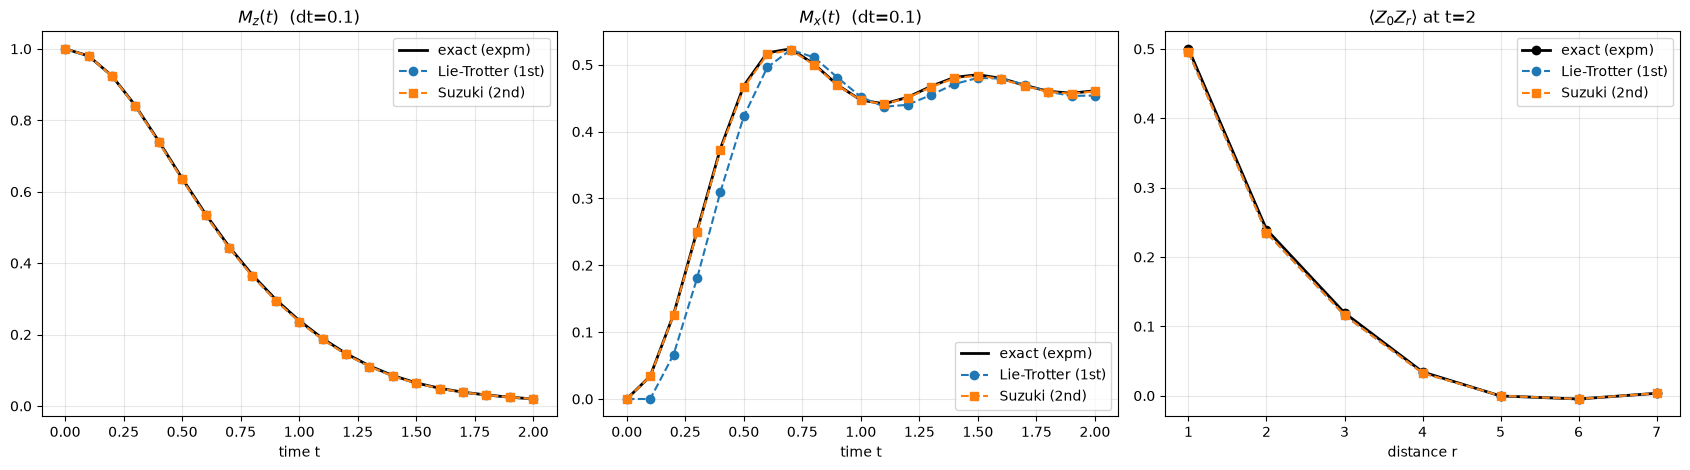

order    n      dt    err_Mz    err_Mx
    1    1  2.0000  6.73e-01  4.61e-01
    1    2  1.0000  6.55e-01  4.47e-01
    1    3  0.6667  2.40e-01  5.26e-01
    1    4  0.5000  9.69e-02  4.69e-01
    1    5  0.4000  6.20e-02  3.75e-01
    1    6  0.3333  4.24e-02  2.94e-01
    1    8  0.2500  2.28e-02  1.87e-01
    1   10  0.2000  1.41e-02  1.47e-01
    1   12  0.1667  9.85e-03  1.25e-01
    1   15  0.1333  6.25e-03  9.44e-02
    1   20  0.1000  3.51e-03  7.07e-02
    1   25  0.0800  2.24e-03  5.56e-02
    1   30  0.0667  1.55e-03  4.54e-02
    1   40  0.0500  8.73e-04  3.39e-02
    1   50  0.0400  5.58e-04  2.67e-02
    1   60  0.0333  3.88e-04  2.22e-02
    1   80  0.0250  2.18e-04  1.66e-02
    1  100  0.0200  1.39e-04  1.32e-02
    1  120  0.0167  9.69e-05  1.10e-02
    1  160  0.0125  5.45e-05  8.19e-03
    1  200  0.0100  3.49e-05  6.54e-03
    1  300  0.0067  1.55e-05  4.34e-03
    2    1  2.0000  6.73e-01  6.29e-01
    2    2  1.0000  6.55e-01  7.85e-01
    2    3  0.6667  2.40e

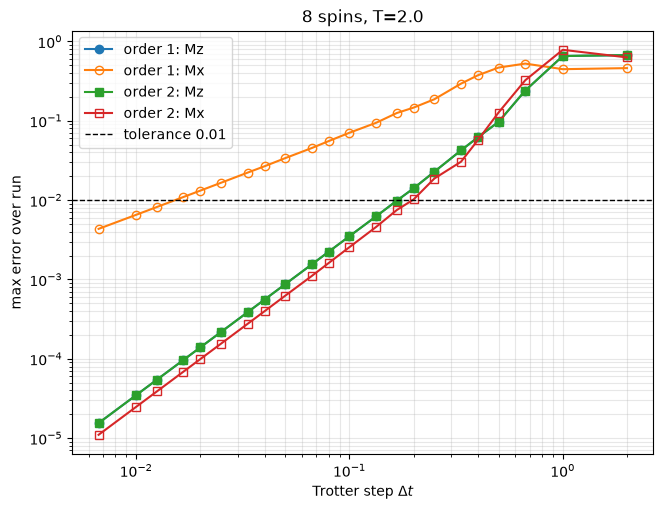


Same-n check: Mz error identical for orders 1 and 2: True


In [4]:
# Beginner requirements: 8 spins, J=h=1, |00000000>, t=2, exact reference from scipy.linalg.expm.
# Run AFTER the main script (this cell reuses its helpers).
from scipy.linalg import expm

NB, JB, hB, TB = 8, 1.0, 1.0, 2.0
HB = tfim_hamiltonian(NB, JB, hB)
HB_mat = HB.to_matrix()
MzB, MxB = avg_op(NB, "Z"), avg_op(NB, "X")
psi0 = Statevector.from_label("0" * NB).data


def exact_traj(n):
    """Exact states at t_k = k*TB/n using scipy.linalg.expm."""
    U = expm(-1j * HB_mat * (TB / n))
    psi = psi0.copy()
    states = [Statevector(psi)]
    for _ in range(n):
        psi = U @ psi
        states.append(Statevector(psi))
    return states


def obs(states, op):
    return np.array([s.expectation_value(op).real for s in states])


def sweep_B(order, n_list):
    rows = []
    for n in n_list:
        dt = TB / n
        tr = trotter_states(HB, NB, dt, n, order)
        ex = exact_traj(n)
        rows.append(dict(n=n, dt=dt,
                         err_mz=np.max(np.abs(obs(tr, MzB) - obs(ex, MzB))),
                         err_mx=np.max(np.abs(obs(tr, MxB) - obs(ex, MxB)))))
    return rows


# ---- 1. Plots at a fixed step (dt = 0.1, n = 20): Mz(t), Mx(t), <Z0 Zr> at t=2 ----
n_plot = 20
ex_p = exact_traj(n_plot)
lie_p = trotter_states(HB, NB, TB / n_plot, n_plot, order=1)
suz_p = trotter_states(HB, NB, TB / n_plot, n_plot, order=2)
t_p = np.linspace(0, TB, n_plot + 1)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, op, name in [(axes[0], MzB, r"$M_z(t)$"), (axes[1], MxB, r"$M_x(t)$")]:
    ax.plot(t_p, obs(ex_p, op), "k-", lw=2, label="exact (expm)")
    ax.plot(t_p, obs(lie_p, op), "o--", label="Lie-Trotter (1st)")
    ax.plot(t_p, obs(suz_p, op), "s--", label="Suzuki (2nd)")
    ax.set_xlabel("time t"); ax.set_title(name + f"  (dt={TB / n_plot})"); ax.grid(alpha=0.3); ax.legend()

r_vals = list(range(1, NB))
corr = lambda st: [st[-1].expectation_value(site_op(NB, {0: "Z", r: "Z"})).real for r in r_vals]
axes[2].plot(r_vals, corr(ex_p), "k-o", lw=2, label="exact (expm)")
axes[2].plot(r_vals, corr(lie_p), "o--", label="Lie-Trotter (1st)")
axes[2].plot(r_vals, corr(suz_p), "s--", label="Suzuki (2nd)")
axes[2].set_xlabel("distance r"); axes[2].set_title(r"$\langle Z_0 Z_r\rangle$ at t=2")
axes[2].grid(alpha=0.3); axes[2].legend()
plt.tight_layout(); plt.show()

# ---- 2. Largest dt with max error < 0.01 over the whole run, for Mz and Mx ----
n_listB = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 40, 50, 60, 80, 100, 120, 160, 200, 300]
resB = {1: sweep_B(1, n_listB), 2: sweep_B(2, n_listB)}

print(f"{'order':>5} {'n':>4} {'dt':>7} {'err_Mz':>9} {'err_Mx':>9}")
for order in (1, 2):
    for r in resB[order]:
        print(f"{order:>5} {r['n']:>4} {r['dt']:>7.4f} {r['err_mz']:>9.2e} {r['err_mx']:>9.2e}")

TOL = 0.01
print(f"\nLargest dt with max error <= {TOL} over the whole run (T={TB}); all smaller dt also pass:\n")
summary = {}
for order, name in [(1, "Lie-Trotter (1st)"), (2, "Suzuki (2nd)")]:
    for key, label in [("err_mz", "Mz"), ("err_mx", "Mx")]:
        r = largest_ok_dt(resB[order], key, TOL)
        if r is None:
            print(f"{name:>18} | {label}: not reached in this sweep (extend n_listB)")
            continue
        depth, cx = circuit_cost(HB, NB, r["dt"], r["n"], order)
        summary[(order, label)] = (r["dt"], r["n"], cx)
        print(f"{name:>18} | {label}: dt = {r['dt']:.4f}  (n = {r['n']:>3} steps)  two-qubit gates (CX) = {cx}")

# ---- 3. Error vs dt with the 0.01 tolerance line ----
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for order, fmt in [(1, "o-"), (2, "s-")]:
    ax.loglog(col(resB[order], "dt"), np.maximum(col(resB[order], "err_mz"), 1e-16), fmt, label=f"order {order}: Mz")
    ax.loglog(col(resB[order], "dt"), np.maximum(col(resB[order], "err_mx"), 1e-16), fmt, mfc="none", label=f"order {order}: Mx")
ax.axhline(TOL, color="k", ls="--", lw=1, label="tolerance 0.01")
ax.set_xlabel(r"Trotter step $\Delta t$"); ax.set_ylabel("max error over run")
ax.set_title(f"8 spins, T={TB}"); ax.grid(alpha=0.3, which="both"); ax.legend()
plt.show()

print("\nSame-n check: Mz error identical for orders 1 and 2:",
      all(abs(a["err_mz"] - b["err_mz"]) < 1e-9 for a, b in zip(resB[1], resB[2])))